# TecnoForms — Del papel al dato
## Proyecto final: clasificación de dígitos manuscritos
**Fecha:** 5 de noviembre de 2026 · **Curso:** Machine Learning y Deep Learning

**Problema:** formularios de inscripción, pagos y solicitudes requieren transcripción manual. Proponemos reconocer respuestas numéricas, convertirlas en un formulario digital revisable y analizarlas por campo.

**Entregable:** aplicación Flask, modelos entrenados, EDA, validación, métricas, evidencias visuales, arquitectura, regresión/K-Means sintéticos, diagrama, informe y respuestas guía.

**Alcance honesto:** los experimentos con dígitos aislados no validan la extracción integral de formularios. Para texto manuscrito libre se necesita corrección manual o un motor HTR adicional. Ninguna predicción debe considerarse una respuesta confirmada sin revisión.

In [1]:
from pathlib import Path
import sys, json, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'app.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
plt.rcParams.update({'figure.facecolor':'#f6f5fa','axes.spines.top':False,'axes.spines.right':False,'font.size':10})
print('Directorio del proyecto:',ROOT.name)

Directorio del proyecto: Entregable


## 1. Datos, procedencia y calidad
Usamos **UCI Optical Recognition of Handwritten Digits**, incluido en `sklearn.load_digits`: 1 797 imágenes de 8×8 píxeles, clases 0–9 e intensidades 0–16. Son datos públicos de escritura real, no formularios empresariales. Fuente: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html

Para las regiones de fotografías se entrena además HOG/SVM con 15 000 imágenes de **MNIST** de 28×28. Se ajusta C con una partición de validación y después se evalúa en los 10 000 ejemplos oficiales de test. Fuente: https://www.tensorflow.org/datasets/catalog/mnist

Los registros de tiempos de procesamiento de la sección 7 son **ficticios**, creados con semilla 42. No deben interpretarse como productividad real de TecnoForms.

Imágenes: (1797, 8, 8) Rango: 0.0 16.0
Valores faltantes: 0
Imágenes duplicadas: 0
Distribución: {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(183), np.int64(4): np.int64(181), np.int64(5): np.int64(182), np.int64(6): np.int64(181), np.int64(7): np.int64(179), np.int64(8): np.int64(174), np.int64(9): np.int64(180)}


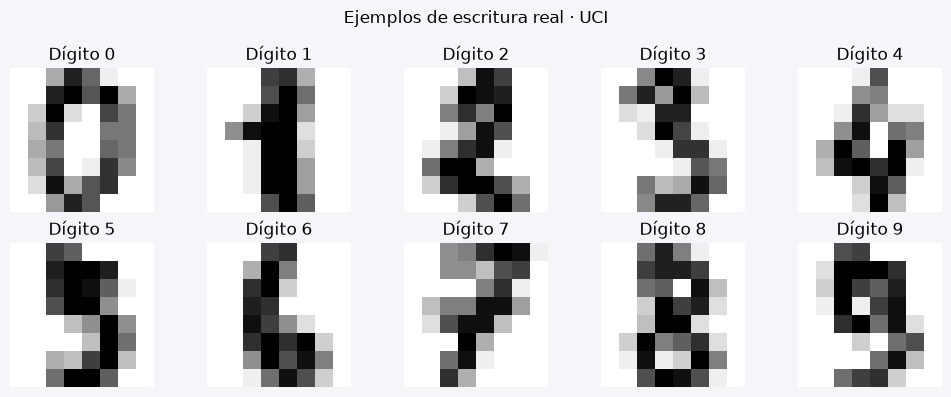

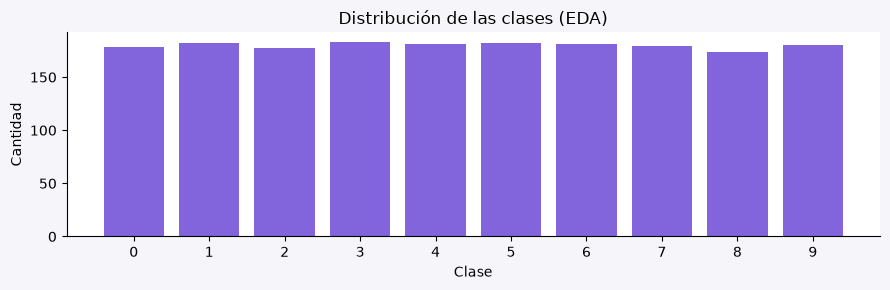

In [2]:
d=load_digits(); X=d.data/16.; y=d.target
print('Imágenes:',d.images.shape,'Rango:',d.data.min(),d.data.max())
print('Valores faltantes:',np.isnan(X).sum())
print('Imágenes duplicadas:',len(X)-len(np.unique(X,axis=0)))
print('Distribución:',dict(zip(*np.unique(y,return_counts=True))))
fig,axs=plt.subplots(2,5,figsize=(10,4))
for digit,ax in enumerate(axs.ravel()):
    ax.imshow(d.images[np.where(y==digit)[0][0]],cmap='gray_r');ax.set_title(f'Dígito {digit}');ax.axis('off')
fig.suptitle('Ejemplos de escritura real · UCI');fig.tight_layout()
fig.savefig(ROOT/'docs/muestras.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(9,3));ax.bar(np.arange(10),np.bincount(y),color='#8265dd')
ax.set(xlabel='Clase',ylabel='Cantidad',title='Distribución de las clases (EDA)',xticks=range(10));fig.tight_layout();fig.savefig(ROOT/'docs/distribucion.png',dpi=150);plt.show()

## 2. Preparación de formularios
1. Validar formato, tamaño y resolución; aplicar orientación EXIF y limitar la resolución.
2. Corregir orientación con el botón de giro; tomar la foto de frente para evitar perspectiva.
3. Convertir RGB a escala de grises y binarizar con Otsu.
4. Retirar líneas largas con apertura morfológica horizontal y vertical.
5. Segmentar componentes conectados dentro de cada región numérica. Ordenar de izquierda a derecha.
6. Recortar cada dígito, conservar proporción, normalizar y centrar en una imagen de 28×28. Extraer HOG para SVM. El modelo de respaldo normaliza a 8×8.
7. Proponer la respuesta y su score. Revisar con la foto, corregir y confirmar antes de persistir.

El OCR Tesseract intenta recuperar rótulos impresos y líneas del formulario. No garantiza texto manuscrito. Si una región contiene varios dígitos unidos o trazos partidos, la segmentación puede producir errores. No se implementó corrección automática de perspectiva: se exige captura frontal.

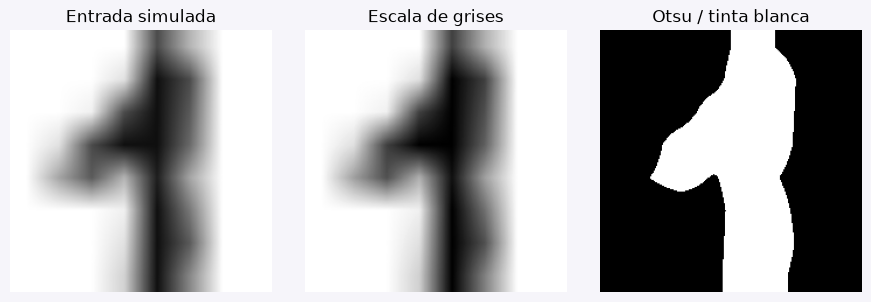

In [3]:
import cv2
sample=(255-cv2.resize(d.images[42].astype('uint8')*15,(224,224))).astype('uint8')
rgb=cv2.cvtColor(sample,cv2.COLOR_GRAY2RGB)
gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
binary=cv2.threshold(gray,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)[1]
fig,axs=plt.subplots(1,3,figsize=(9,3))
for ax,im,t in zip(axs,[rgb,gray,binary],['Entrada simulada','Escala de grises','Otsu / tinta blanca']):
    ax.imshow(im,cmap='gray');ax.set_title(t);ax.axis('off')
fig.tight_layout();fig.savefig(ROOT/'docs/preprocesamiento.png',dpi=150);plt.show()

## 3. Algoritmos y entrenamiento sin fuga de datos
Comparamos **KNN**, **SVM RBF** y una **MLP**. KNN ofrece una referencia simple; SVM funciona bien con muestras pequeñas; MLP aprende representaciones no lineales. No usamos CNN en este prototipo: la consigna exige capas convolucionales solamente si se elige CNN.

Separamos 80% entrenamiento y 20% test de forma estratificada con semilla 42. `GridSearchCV` realiza 3 pliegues en entrenamiento y selecciona hiperparámetros por F1 macro. El test se consulta después de ajustar. Se elige el modelo por validación, no por su puntuación de test.

Grillas: KNN k={3,5}; SVM C={1,10}, gamma=scale; MLP alpha={0.0001,0.001}. Las advertencias de convergencia de MLP a 180 iteraciones indican que conviene probar más iteraciones con validación, no esconder la advertencia.

In [4]:
from tools.train import train
metrics=train()
for name,r in metrics['models'].items():
    print(f"{name:4s} | CV F1={r['cv_f1']:.4f} | test accuracy={r['accuracy']:.4f} | precision={r['precision_macro']:.4f} | recall={r['recall_macro']:.4f} | F1={r['f1_macro']:.4f} | {r['params']}")
print('Modelo seleccionado por validación:',metrics['selected'])

KNN 0.9861111111111112


C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (6 outputs left out)

C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (180) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP 0.9805555555555555


C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (180) reached and the optimization hasn't converged yet.
  warnings.warn(


KNN  | CV F1=0.9825 | test accuracy=0.9861 | precision=0.9866 | recall=0.9859 | F1=0.9859 | {'n_neighbors': 3}
SVM  | CV F1=0.9867 | test accuracy=0.9917 | precision=0.9920 | recall=0.9915 | F1=0.9916 | {'C': 1, 'gamma': 'scale'}
MLP  | CV F1=0.9684 | test accuracy=0.9806 | precision=0.9810 | recall=0.9803 | F1=0.9804 | {'alpha': 0.0001}
Modelo seleccionado por validación: SVM


## 4. Evaluación e interpretación
**Exactitud:** proporción total de aciertos. **Precisión por clase:** entre los dígitos predichos como una clase, cuántos lo eran. **Recall:** cuántos ejemplos reales de esa clase se recuperaron. **F1:** media armónica de precisión y recall. La media macro asigna el mismo peso a cada dígito.

La matriz de confusión muestra errores concretos (fila real, columna predicha). Los resultados altos en imágenes pequeñas estandarizadas no garantizan reconocimiento de números en sombras, fotografías oblicuas o trazos conectados. El score del clasificador no equivale a una confianza calibrada de todo el formulario.

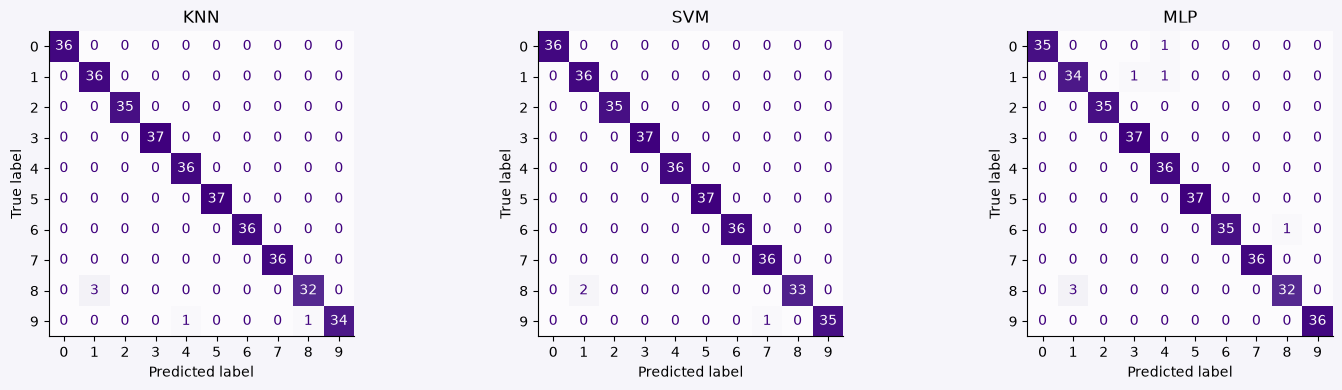


 KNN
Clase | precisión | recall | F1 | soporte
0 1.0 1.0 1.0 36.0
1 0.9231 1.0 0.96 36.0
2 1.0 1.0 1.0 35.0
3 1.0 1.0 1.0 37.0
4 0.973 1.0 0.9863 36.0
5 1.0 1.0 1.0 37.0
6 1.0 1.0 1.0 36.0
7 1.0 1.0 1.0 36.0
8 0.9697 0.9143 0.9412 35.0
9 1.0 0.9444 0.9714 36.0

 SVM
Clase | precisión | recall | F1 | soporte
0 1.0 1.0 1.0 36.0
1 0.9474 1.0 0.973 36.0
2 1.0 1.0 1.0 35.0
3 1.0 1.0 1.0 37.0
4 1.0 1.0 1.0 36.0
5 1.0 1.0 1.0 37.0
6 1.0 1.0 1.0 36.0
7 0.973 1.0 0.9863 36.0
8 1.0 0.9429 0.9706 35.0
9 1.0 0.9722 0.9859 36.0

 MLP
Clase | precisión | recall | F1 | soporte
0 1.0 0.9722 0.9859 36.0
1 0.9189 0.9444 0.9315 36.0
2 1.0 1.0 1.0 35.0
3 0.9737 1.0 0.9867 37.0
4 0.9474 1.0 0.973 36.0
5 1.0 1.0 1.0 37.0
6 1.0 0.9722 0.9859 36.0
7 1.0 1.0 1.0 36.0
8 0.9697 0.9143 0.9412 35.0
9 1.0 1.0 1.0 36.0


In [5]:
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,(name,r) in zip(axs,metrics['models'].items()):
    ConfusionMatrixDisplay(np.array(r['confusion_matrix']),display_labels=range(10)).plot(ax=ax,colorbar=False,cmap='Purples',values_format='d');ax.set_title(name)
fig.tight_layout();fig.savefig(ROOT/'docs/matrices_confusion.png',dpi=150);plt.show()
for name,r in metrics['models'].items():
    print('\n',name)
    print('Clase | precisión | recall | F1 | soporte')
    for digit in map(str,range(10)):
        v=r['report'][digit];print(digit,*(round(v[k],4) for k in ['precision','recall','f1-score','support']))

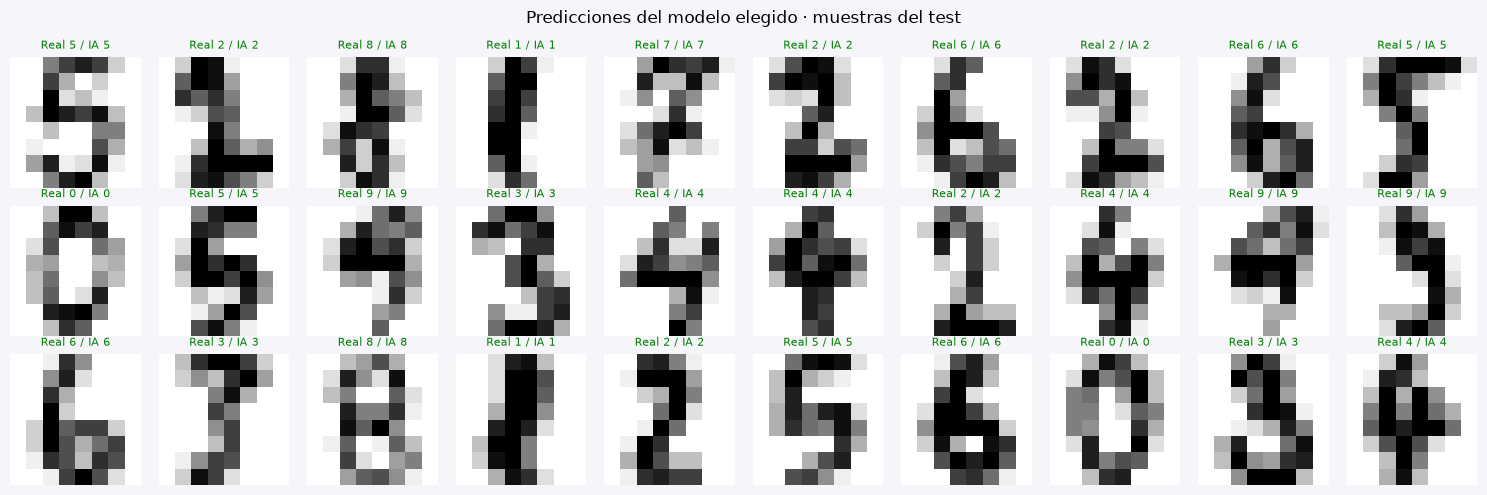

In [6]:
s=np.load(ROOT/'data/benchmark_samples.npz')
fig,axs=plt.subplots(3,10,figsize=(15,5))
for i,ax in enumerate(axs.ravel()):
    ax.imshow(s['images'][i],cmap='gray_r');real=int(s['truth'][i]);pred=int(s['prediction'][i]);ax.set_title(f'Real {real} / IA {pred}',fontsize=8,color='green' if real==pred else 'crimson');ax.axis('off')
fig.suptitle('Predicciones del modelo elegido · muestras del test');fig.tight_layout();fig.savefig(ROOT/'docs/predicciones.png',dpi=150);plt.show()

## 5. Arquitectura y funcionamiento interno de la red
**64 entradas → Dense 64 ReLU → Dense 32 ReLU → Dense 10 softmax**. Total: 6 570 parámetros (pesos y sesgos). Optimizador Adam, learning rate inicial 0.001, lotes automáticos y entropía cruzada multiclase.

Cada neurona calcula z = W·x+b y aplica una activación. ReLU conserva max(0,z); softmax produce una distribución entre 10 clases. La pérdida compara esa distribución con la etiqueta real. Retropropagación calcula gradientes; Adam actualiza pesos para reducir la pérdida. La regularización L2 alpha limita magnitudes de pesos. Validar controla la generalización.

La MLP se implementa realmente en `tools/train.py`; SVM puede ser seleccionado para inferencia si generaliza mejor en validación. El motor de fotografías HOG/SVM es un segundo experimento, no una CNN.

Parámetros MLP: 6570
Experimento MNIST independiente:
{
  "dataset": "MNIST",
  "train": 15000,
  "validation": 3000,
  "test": 10000,
  "seed": 42,
  "feature": "HOG 28x28 / 324 features",
  "search": [
    {
      "C": 2,
      "validation_accuracy": 0.9863333333333333
    },
    {
      "C": 8,
      "validation_accuracy": 0.986
    }
  ],
  "C": 2,
  "accuracy": 0.9904,
  "precision_macro": 0.9903700609557902,
  "recall_macro": 0.9903544558915944,
  "f1_macro": 0.9903516979028165
}


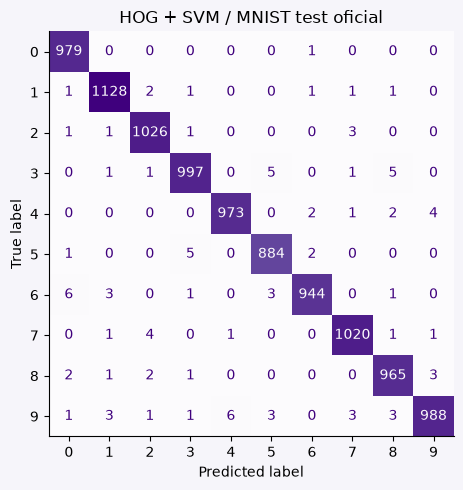

In [7]:
print('Parámetros MLP:',(64+1)*64+(64+1)*32+(32+1)*10)
photo_path=ROOT/'models/photo_metrics.json'
if photo_path.exists():
    photo=json.loads(photo_path.read_text());print('Experimento MNIST independiente:')
    print(json.dumps({k:v for k,v in photo.items() if k!='confusion_matrix'},indent=2))
    fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay(np.array(photo['confusion_matrix'])).plot(ax=ax,colorbar=False,cmap='Purples');ax.set_title('HOG + SVM / MNIST test oficial');fig.tight_layout();fig.savefig(ROOT/'docs/mnist_confusion.png',dpi=150);plt.show()
else:
    print('Ejecutar python tools/train_photo.py para medir MNIST antes de interpretar este motor.')

## 6. Diagrama de solución
La autorización se comprueba en cada consulta de formularios. La foto se procesa en memoria; solo se guardan las respuestas revisadas. Los diagramas también están disponibles dentro de la aplicación (Cómo funciona y Laboratorio ML).

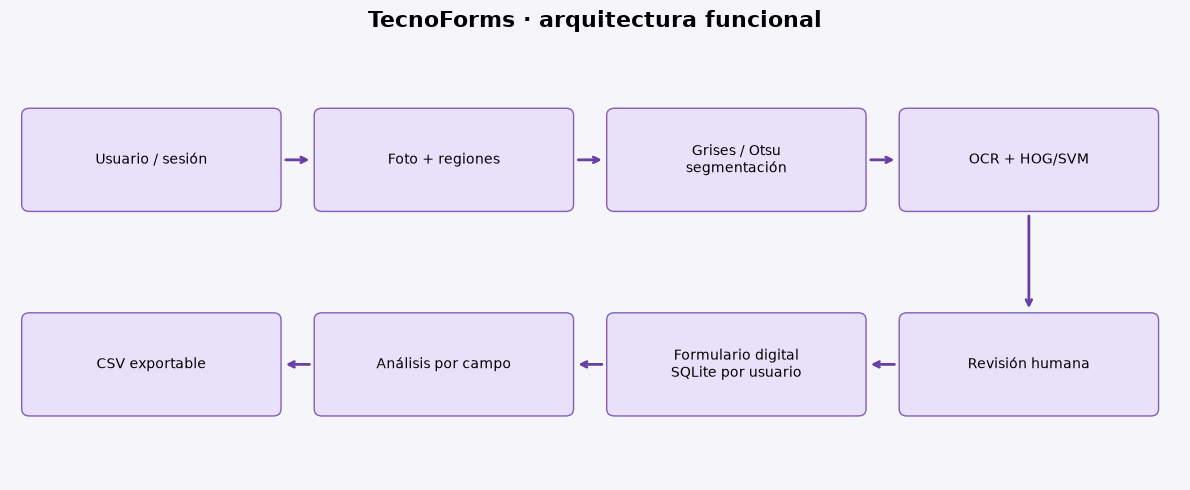

In [8]:
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(12,5));ax.set_xlim(0,12);ax.set_ylim(0,5);ax.axis('off')
nodes=[(.2,3.1,'Usuario / sesión'),(3.2,3.1,'Foto + regiones'),(6.2,3.1,'Grises / Otsu\nsegmentación'),(9.2,3.1,'OCR + HOG/SVM'),(9.2,.8,'Revisión humana'),(6.2,.8,'Formulario digital\nSQLite por usuario'),(3.2,.8,'Análisis por campo'),(.2,.8,'CSV exportable')]
for x,y,text in nodes:
    ax.add_patch(FancyBboxPatch((x,y),2.5,1,boxstyle='round,pad=.08',fc='#e9e1fa',ec='#8160b9'));ax.text(x+1.25,y+.5,text,ha='center',va='center',fontsize=10)
for x1,y1,x2,y2 in [(2.8,3.6,3.1,3.6),(5.8,3.6,6.1,3.6),(8.8,3.6,9.1,3.6),(10.45,3,10.45,1.9),(9.1,1.3,8.8,1.3),(6.1,1.3,5.8,1.3),(3.1,1.3,2.8,1.3)]:ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops=dict(arrowstyle='->',color='#6640a4',lw=2))
ax.set_title('TecnoForms · arquitectura funcional',fontweight='bold',fontsize=16);fig.tight_layout();fig.savefig(ROOT/'docs/diagrama.png',dpi=160);fig.savefig(ROOT/'docs/diagrama.svg');plt.show()

## 7. Datos ficticios: regresión, K-Means y red neuronal
La regresión estima tiempos sintéticos según cantidad de campos y calidad ficticia. Se evalúa con test separado; no mide ahorros reales. K-Means agrupa esos formularios ficticios por características operativas, con escalado. Sus grupos no se equiparan a dígitos y no reemplazan al clasificador supervisado.

Regresión, test ficticio: MAE 0.216 segundos; R² 0.992
K-Means ficticio: silhouette 0.384


C:\Users\LORENA\AppData\Roaming\Python\Python314\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP de datos ficticios, exactitud test: 1.0


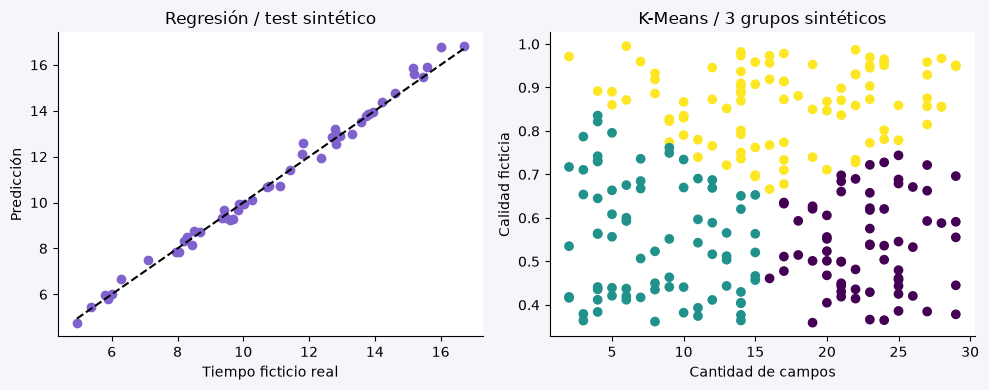

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,r2_score,silhouette_score
import csv
rng=np.random.default_rng(42);n=240
counts=rng.integers(2,30,n);quality=rng.uniform(.35,1,n)
times=2+.45*counts+4*(1-quality)+rng.normal(0,.3,n)
features=np.c_[counts,quality]
a,b,c,e=train_test_split(features,times,test_size=.2,random_state=42)
reg=LinearRegression().fit(a,c);prediction=reg.predict(b)
print('Regresión, test ficticio: MAE',round(mean_absolute_error(e,prediction),3),'segundos; R²',round(r2_score(e,prediction),3))
scaled=StandardScaler().fit_transform(features)
km=KMeans(n_clusters=3,n_init=10,random_state=42).fit(scaled)
print('K-Means ficticio: silhouette',round(silhouette_score(scaled,km.labels_),3))
from sklearn.neural_network import MLPClassifier
# A separate neural experiment on explicitly fictitious form records.
# Labels are generated from a rule, never from the measured target time.
synthetic_labels=((quality>.65)&(counts<20)).astype(int)
sa,sb,sc,sd=train_test_split(features,synthetic_labels,test_size=.2,stratify=synthetic_labels,random_state=42)
from sklearn.pipeline import make_pipeline
synthetic_mlp=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(16,8),max_iter=600,random_state=42))
synthetic_mlp.fit(sa,sc)
print('MLP de datos ficticios, exactitud test:',round(synthetic_mlp.score(sb,sd),3))
with (ROOT/'data/formularios_ficticios.csv').open('w',newline='',encoding='utf-8') as stream:
    w=csv.writer(stream);w.writerow(['campos','calidad_sintetica','tiempo_sintetico_s','cluster'])
    w.writerows(zip(counts,quality,times,km.labels_))
fig,axs=plt.subplots(1,2,figsize=(10,4));axs[0].scatter(e,prediction,c='#8062ce');axs[0].plot([e.min(),e.max()],[e.min(),e.max()],'k--');axs[0].set(xlabel='Tiempo ficticio real',ylabel='Predicción',title='Regresión / test sintético')
axs[1].scatter(counts,quality,c=km.labels_,cmap='viridis');axs[1].set(xlabel='Cantidad de campos',ylabel='Calidad ficticia',title='K-Means / 3 grupos sintéticos');fig.tight_layout();fig.savefig(ROOT/'docs/sinteticos.png',dpi=150);plt.show()

## 8. Respuestas a las preguntas guía
**1. Variabilidad y calidad.** Las personas cambian inclinación, tamaño, presión, forma y separación. Un 1 puede parecer 7; 3 y 8 se confunden si el trazo está cerrado. Ruido, sombras, líneas de tablas y perspectiva afectan segmentación y clasificación. La muestra académica no contiene toda esa diversidad.

**2. Elección del algoritmo.** KNN no aprende pesos y consulta vecinos, por lo que la latencia crece con los ejemplos y la distancia depende del escalado. SVM RBF aprende fronteras no lineales y es eficaz con pocos datos. MLP aprende pesos jerárquicos y requiere controlar convergencia y sobreajuste. La comparación medida y su CV justifican elegir SVM para este benchmark; no existe un ganador universal.

**3. Preprocesamiento.** Orientación correcta, gris, binarización Otsu, supresión cuidadosa de líneas, recorte, centrado y normalización ayudan. Umbral adaptativo puede mejorar iluminación desigual pero debe validarse. No se debe suavizar tanto que desaparezcan trazos finos. Una transformación de perspectiva sería una ampliación útil.

**4. Métricas.** Exactitud resume; precisión limita falsas asignaciones; recall cuantifica omisiones por clase; F1 equilibra ambas. Matriz de confusión localiza errores. Además de dígitos se debe medir exactitud de cadena completa, campo y formulario, tasa de corrección y tiempo humano. El producto aún no tiene ese benchmark de fotos.

**5. Mejoras.** Recopilar fotos consentidas con varias personas y cámaras; separar entrenamiento y test por escritor/formulario; etiquetar campos y dígitos; aumentar con rotaciones, sombras y perspectiva; comparar CNN y HTR; ajustar hiperparámetros exclusivamente en validación; calibrar probabilidades y fijar umbrales de revisión. Reentrenar solo con correcciones verificadas, versionar el modelo y evaluar test independiente.

## 9. Factibilidad, seguridad, salud y ambiente
El prototipo es viable técnicamente para un flujo asistido por persona: fotografía → propuesta → corrección → CSV/análisis. La viabilidad comercial requiere evaluación de campo y persistencia duradera. No se utilizan predicciones para decidir admisión, pagos o calificaciones automáticamente.

Contraseñas con hash, cookies HttpOnly/SameSite, token CSRF para operaciones autenticadas, SQL parametrizado, acceso por usuario, límites de archivos y protección contra fórmulas CSV. Las fotos no se guardan. SQLite temporal en Render gratuito exige exportar los formularios antes de reinicios. Faltan recuperación de contraseña, verificación de correo y limitación distribuida de intentos para una versión productiva.

Ergonomía: buena luz, postura adecuada y pausas visuales. Ambiente: digitalizar evita reimpresiones y debe acompañarse de eliminación responsable de copias temporales y reducción de cómputo innecesario.

## 10. Evidencias y consideraciones para el entregable
|Requisito|Evidencia|
|---|---|
|Propuesta fundamentada|Secciones 1–3, 8–9 e informe|
|Algoritmos supervisados y comparación|Código ejecutado sección 3 y métricas de sección 4|
|Preprocesamiento y segmentación|Sección 2, `vision.py` y aplicación|
|Red y arquitectura|MLP entrenada, sección 5|
|Entrenamiento, CV e hiperparámetros|`tools/train.py`, sección 3|
|Test, precisión, recall, F1 y matriz|Sección 4, JSON de métricas|
|Regresión, K-Means y red con datos ficticios|Sección 7 y CSV sintético|
|Predicción versus etiquetas reales|Gráfico de sección 4|
|Esquema o diagrama alineado|Sección 6, SVG e interfaz|
|Informe y preguntas guía|Secciones 8–9 y `docs/Informe_TecnoForms.md`|

## 11. Fuentes y relación con el curso
- Semanas 9–10: Python, estadística, supervisado, redes, regresión y agrupación. Se implementan EDA, MLP, SVM/KNN, regresión y K-Means.
- Semanas 11–12: OpenCV, manipulación de imágenes, grises y filtros. Se aplican transformación de imagen y segmentación; no se copia código del curso con errores.
- Consigna: PIAD-427_TRABAJOFINAL.pdf suministrado por la estudiante. Se toma como referencia académica, no como permiso para acciones externas.
- sklearn MLP: https://scikit-learn.org/stable/modules/neural_networks_supervised.html
- sklearn digits: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
- MNIST: https://www.tensorflow.org/datasets/catalog/mnist
- Tesseract y calidad: https://tesseract-ocr.github.io/tessdoc/ImproveQuality.html
- OpenCV umbralización: https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html

## Actualización del lector de formularios — 6 de noviembre de 2026

La versión 2 añade un modelo gratuito **TrOCR small handwritten cuantizado en ONNX**, preentrenado con IAM, para reconocer líneas manuscritas. No se reentrenó con las imágenes privadas de la usuaria. La inferencia se ejecuta en el servidor de la aplicación; no utiliza una API externa de pago.

Flujo: **foto → rectificación/iluminación → rótulos y columnas → recortes por campo → TrOCR/OCR español o HOG/SVM → casillas → revisión visual → CSV/análisis**.

El lector distingue espacios vacíos, muestra recortes y alternativas, procesa trabajos con progreso/cancelación y permite seleccionar texto o dígitos manualmente. Los recortes no se persisten al guardar formularios.

**Límites:** IAM contiene principalmente escritura inglesa. El español cursivo, nombres, signos y decoraciones todavía pueden generar errores. Las cuatro imágenes suministradas son ejemplos de desarrollo, no un conjunto de test independiente. Las métricas UCI/MNIST de este cuaderno siguen correspondiendo a dígitos aislados; no representan exactitud del lector completo.

Implementación: `form_reader.py`, `handwriting.py`, `tools/download_htr.py`. Detalles y evaluación: `docs/Mejoras_Lector_V2.md`. Fuente: https://huggingface.co/Xenova/trocr-small-handwritten (licencia MIT según ficha del modelo).
